# Credit Pre-Screening Engine — Loan Intake Optimisation
### Calibo AI Academy · Phase 2 · Mini Use Case 02 · Path 3

**Dataset:** `MUC02_Credit_PreScreening_Dataset.csv`  
**Target:** `decision` — encode `Declined = 1`, `Approved = 0`  
**Scope:** CBIM Problem Canvas, Steps 5.1–5.11, plus optional Step 5.12 (K-Means).

> **Important:** This notebook is a learning and decision-support prototype built on a simulated historical dataset. It does not establish that any model is safe or legally appropriate for real lending decisions. Thresholds and results must be validated on future data, reviewed by credit policy, risk, compliance and fairness specialists, and monitored after any controlled pilot.

## How to run this notebook
1. Put this notebook and `MUC02_Credit_PreScreening_Dataset.csv` in the same folder.
2. Install the libraries if required: `pip install pandas numpy matplotlib seaborn scikit-learn jupyter`.
3. Run all cells from top to bottom. The analysis prints dataset-specific findings; do not replace measured results with guessed numbers.
4. Review every interpretation and adapt the final recommendation to the actual outputs.

## Assignment map
- **Before coding:** CBIM Problem Canvas.
- **Part 1:** Steps 5.1–5.7 — inspect and clean data, understand historical approval patterns, engineer features, build logistic regression, choose an auto-decline threshold, check fairness and write an interim briefing.
- **Part 2:** Steps 5.8–5.11 — build a reusable pipeline, compare four models using five-fold stratified cross-validation, design two decision lanes and recommend a policy.
- **Optional stretch:** Step 5.12 — K-Means applicant segmentation.

Each major step includes both code and a Markdown explanation of what it means for the credit team.

# CBIM Problem Canvas

Complete this canvas **before** analysing model results. The answers below translate the case brief into a working problem definition; revisit them after the analysis.

| Canvas element | Initial answer |
|---|---|
| **Situation (S)** | A retail lending unit reviews personal-loan applications manually. The case describes approximately 3,000 applications each month and about 25 minutes per review. |
| **Complication (C)** | Manual review consumes analyst capacity, while clear-cut cases may not need the same level of judgement as borderline applications. Automating decisions can also wrongly reject suitable applicants or route risky applicants too quickly. |
| **Question (Q)** | How much of the review queue can be safely routed to auto-decline or fast-track lanes using six months of historical decisions, while meeting both 5% error limits? |
| **SSOT** | The provided CSV is the single source of truth for this exercise. `decision` is the historical final decision recorded by the credit team; it is the supervised-learning target, not an independently verified measure of future repayment performance. |
| **Success definition** | For auto-decline, no more than 5% of that lane may be historically approved. For fast-track, no more than 5% of that lane may be historically declined. Among threshold pairs satisfying both constraints, maximise the share routed away from full manual review. Also report model performance, fairness gaps, explainability and estimated analyst time. |
| **Primary stakeholder** | The Credit Policy Analyst, who must explain the proposal to the Head of Retail Lending. Other affected stakeholders include analysts and applicants. |

**Why this matters:** the success criterion is not accuracy alone. It is safe queue reduction under explicit risk constraints, with human oversight and a defensible fairness position.

# 1. Imports and reproducibility

We use Pandas and NumPy for data work, Matplotlib and Seaborn for plots, and scikit-learn for preprocessing, models, cross-validation and evaluation. A fixed random seed makes the train/test split reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, roc_auc_score
)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

DATA_PATH = "MUC02_Credit_PreScreening_Dataset.csv"

# 5.1 — Load, inspect and clean

### What the question asks
1. Check the dataset shape, data types, missing values and overall approval rate.
2. Find which employment types account for missing `monthly_income`, then choose and justify an imputation approach.
3. For missing `credit_score`, inspect `credit_history_months`. These records should not be dropped if they represent applicants with no credit history.
4. Investigate the maximum `monthly_income`. A few unusually large values may represent annual income entered in a monthly-income field.

### Cleaning choices used here
- Preserve the original dataset in `raw_df`.
- Treat missing credit scores with `credit_history_months == 0` as **new-to-credit (NTC)**, retain those rows and create an `is_ntc` indicator.
- The case contains a small tail of income values above ₹3,00,000/month. Because some look like annual amounts entered in a monthly field, flag these values for review and, for this baseline exercise, treat them as suspect/missing before imputation. This is a **transparent heuristic, not a universal banking rule**; a real bank should validate against source documents and business rules.
- Impute income using the median within `employment_type`, with an overall median fallback. Median is less sensitive to extreme values than the mean.
- Keep a flag for suspected income entries so the data-quality issue remains visible.

The cleaning decisions must be documented because a reviewer needs to understand what was changed and why.

In [22]:
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()

print("Shape:", df.shape)
display(df.head())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("\nDecision counts:")
display(df["decision"].value_counts(dropna=False).to_frame("count"))

approval_rate = (df["decision"].astype(str).str.strip().str.lower() == "approved").mean()
print(f"Overall historical approval rate: {approval_rate:.1%}")
print(f"Overall historical decline rate: {1 - approval_rate:.1%}")

print("\nMissing income by employment type:")
display(
    df.loc[df["monthly_income"].isna()]
      .groupby("employment_type").size()
      .sort_values(ascending=False).rename("missing_income_rows").to_frame()
)

print("\nMissing credit score vs credit history months:")
display(
    df.loc[df["credit_score"].isna(), "credit_history_months"]
      .value_counts(dropna=False).sort_index().rename("rows").to_frame()
)

print("\nLargest reported monthly incomes:")
display(df.nlargest(15, "monthly_income")[
    ["application_id", "employment_type", "monthly_income", "existing_emi", "decision"]
])

print("\nIncome values above ₹350,000:", int((df["monthly_income"] > 350_000).sum()))

Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined



Data types:


,dtype
application_id,object
application_date,object
age,int64
gender,object
city,object
city_tier,int64
employment_type,object
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



Missing values:


...


Missing credit score vs credit history months:


,rows
credit_history_months,
0,1039



Largest reported monthly incomes:


,application_id,employment_type,monthly_income,existing_emi,decision
1467,APP101468,Salaried,1656000.0,16500.0,Declined
300,APP100301,Salaried,1254000.0,0.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,Approved
2488,APP102489,Salaried,972000.0,0.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,Declined
9261,APP109262,Salaried,702000.0,0.0,Approved



Income values above ₹350,000: 20


### Interpretation guide for Step 5.1
Read the printed outputs before moving on. Record the actual approval rate and the employment types with the most missing income values. If the missing credit scores align with zero months of credit history, that supports the interpretation that they are NTC cases rather than ordinary data-entry errors.

The ₹3,00,000 cutoff is used only to flag a very small suspicious tail for this exercise. It should be checked with the data owner: some people genuinely earn more than this per month. We preserve the raw data and an explicit flag so this decision is auditable. The target is not imputed, and rows are not dropped simply because a credit score is blank.

In [21]:
df.duplicated().sum()

np.int64(0)

In [23]:
# Standardise the target labels defensively.
df["decision"] = df["decision"].astype(str).str.strip().str.title()
valid_decisions = {"Approved", "Declined"}
unexpected = sorted(set(df["decision"].dropna()) - valid_decisions)
if unexpected:
    raise ValueError(f"Unexpected decision labels found: {unexpected}")

# Flag implausibly high monthly income entries for review, preserving original values.
INCOME_REVIEW_CUTOFF = 350_000
df["income_suspect_flag"] = (df["monthly_income"] > INCOME_REVIEW_CUTOFF).astype(int)
df["monthly_income_raw"] = df["monthly_income"]
df.loc[df["income_suspect_flag"] == 1, "monthly_income"] = np.nan

# Establish the reproducible stratified split indices before estimating imputation values.
# This lets the imputation statistics come from training rows only.
_pretrain_idx, _pretest_idx = train_test_split(
    df.index, test_size=0.20, stratify=df["decision"], random_state=RANDOM_STATE
)

# Median imputation statistics are learned from the training portion only.
income_group_medians = df.loc[_pretrain_idx].groupby("employment_type")["monthly_income"].median()
overall_income_median = df.loc[_pretrain_idx, "monthly_income"].median()

def fill_income(row):
    if pd.notna(row["monthly_income"]):
        return row["monthly_income"]
    group_median = income_group_medians.get(row["employment_type"], np.nan)
    return group_median if pd.notna(group_median) else overall_income_median

df["monthly_income"] = df.apply(fill_income, axis=1)

# New-to-credit flag: missing score plus no history is the case definition.
df["is_ntc"] = (
    df["credit_score"].isna() & (df["credit_history_months"] == 0)
).astype(int)

# Keep an audit view of remaining missing values.
print("Income values imputed:", int(raw_df["monthly_income"].isna().sum() + (raw_df["monthly_income"] > INCOME_REVIEW_CUTOFF).sum()))
print("Suspected income entries flagged:", int(df["income_suspect_flag"].sum()))
print("NTC applicants identified:", int(df["is_ntc"].sum()))
print("\nRemaining missing values:")
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

Income values imputed: 461
Suspected income entries flagged: 20
NTC applicants identified: 1039

Remaining missing values:


,missing_count
credit_score,1039
monthly_income_raw,441
age,0
gender,0
application_id,0
application_date,0
city_tier,0
city,0
monthly_income,0
employment_type,0


# 5.2 — What drives approval today?

### What the question asks
Group credit scores into the specified bands: **below 600, 600–649, 650–699, 700–749, 750–799, 800+**, plus a separate **No score** group. Plot the historical approval rate for each band and for each employment type.

### Why it matters
This is descriptive analysis of the bank's existing decisions. It helps identify patterns that a model may learn, such as whether approvals fall sharply below a particular score. These are associations in historical decisions, not proof that a factor causes a decision or that the historical policy is fair.

,approval_rate,applications
credit_score_band,,
Below 600,0.020325,246
600–649,0.032154,933
650–699,0.325030,2529
700–749,0.543678,3377
750–799,0.771971,2526
800+,0.851852,1350
No score,0.538980,1039


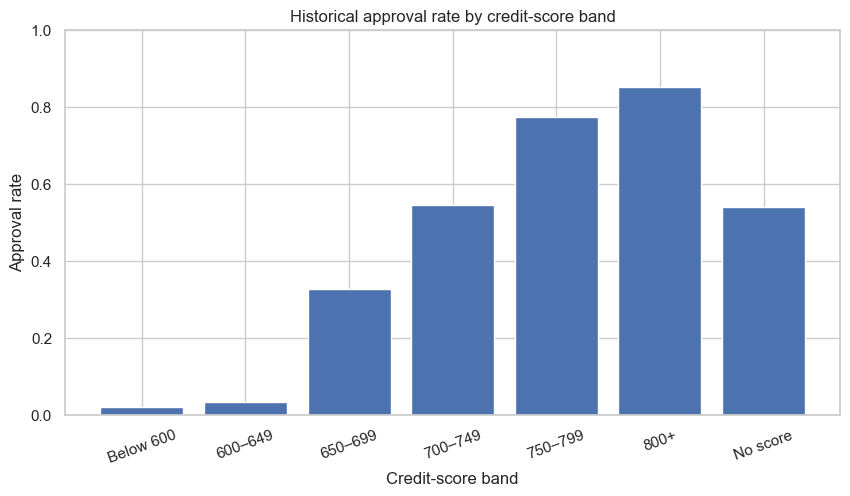

,approval_rate,applications
employment_type,,
Salaried,0.583676,7057
Business Owner,0.511721,1749
Self-Employed Professional,0.505602,1428
Gig / Contract,0.349377,1766


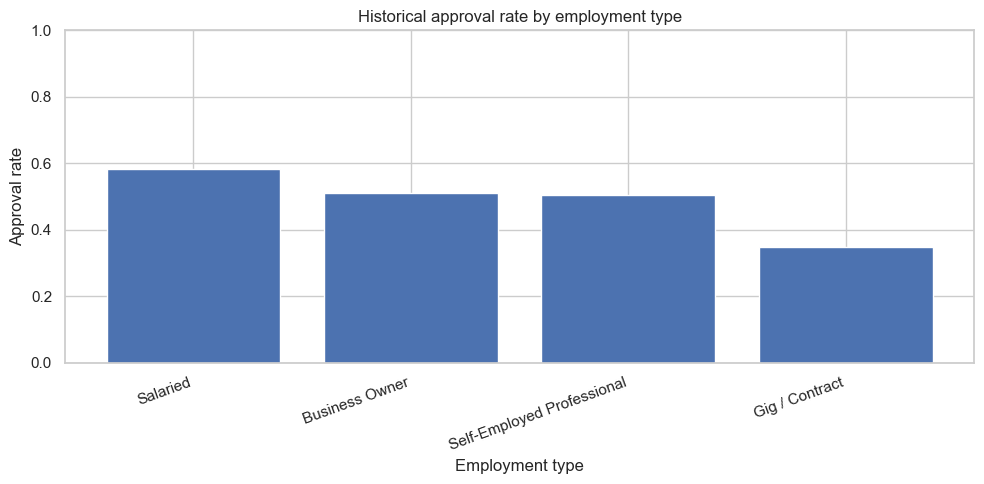

In [4]:
def score_band(score):
    if pd.isna(score):
        return "No score"
    if score < 600:
        return "Below 600"
    if score < 650:
        return "600–649"
    if score < 700:
        return "650–699"
    if score < 750:
        return "700–749"
    if score < 800:
        return "750–799"
    return "800+"

score_order = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+", "No score"]
df["credit_score_band"] = df["credit_score"].apply(score_band)

approval_by_score = (
    df.assign(approved=(df["decision"] == "Approved").astype(int))
      .groupby("credit_score_band")["approved"].agg(["mean", "count"])
      .reindex(score_order)
)
display(approval_by_score.rename(columns={"mean": "approval_rate", "count": "applications"}))

plt.figure(figsize=(10, 5))
plt.bar(approval_by_score.index.astype(str), approval_by_score["mean"].to_numpy())
plt.title("Historical approval rate by credit-score band")
plt.xlabel("Credit-score band")
plt.ylabel("Approval rate")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

approval_by_employment = (
    df.assign(approved=(df["decision"] == "Approved").astype(int))
      .groupby("employment_type")["approved"].agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)
display(approval_by_employment.rename(columns={"mean": "approval_rate", "count": "applications"}))

plt.figure(figsize=(10, 5))
plt.bar(approval_by_employment.index.astype(str), approval_by_employment["mean"].to_numpy())
plt.title("Historical approval rate by employment type")
plt.xlabel("Employment type")
plt.ylabel("Approval rate")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Interpretation questions for Step 5.2
Use the plots and table to answer in your own words:
1. Is there a score band below which approval is rare?
2. What might that reveal about the bank's implicit credit policy?
3. How does the approval rate for applicants with no score compare with scored applicants?
4. Does approval differ by employment type?

Include sample sizes when interpreting a group: a rate based on few applications is less stable than a rate based on many. Do not claim that a group characteristic causes approval or decline based on a bar chart alone.

# 5.3 — Engineer affordability features

Create the three features requested in the brief:

- `foir = (existing_emi + proposed_emi) / monthly_income`
- `loan_to_income = loan_amount / (monthly_income × 12)`
- `is_ntc = 1` for applicants with no credit score and no credit history, otherwise `0`

Then group FOIR into **below 30%, 30–40%, 40–50%, 50–55%, above 55%** and plot approval rate.

### Business meaning
FOIR measures the share of monthly income committed to existing and proposed EMIs. Loan-to-income compares the requested amount with annual declared income. Higher values may indicate affordability pressure, but the bank must validate the policy limits against its own risk appetite and applicable rules.

,approval_rate,applications
foir_band,,
Below 30%,0.654870,5482
30–40%,0.588329,2502
40–50%,0.479001,1762
50–55%,0.325800,531
Above 55%,0.159025,1723


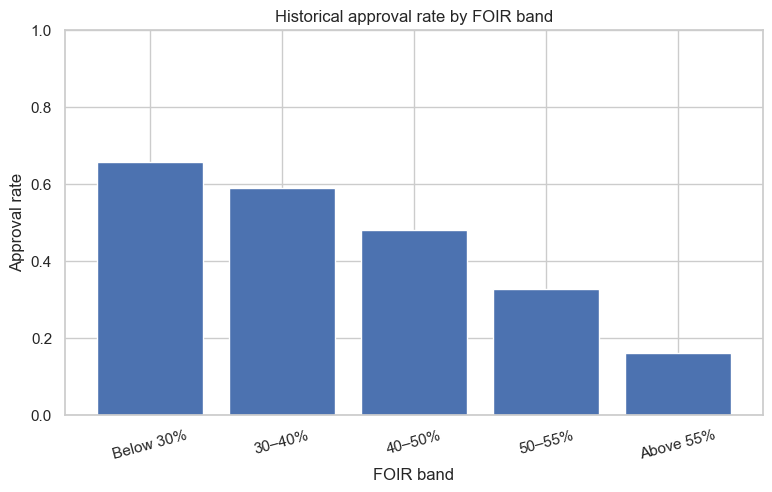

,count,mean,std,min,25%,50%,75%,max
foir,12000.0,0.358882,0.208110,0.020238,0.214612,0.316667,0.450722,3.393333
loan_to_income,12000.0,0.532330,0.228812,0.044444,0.347222,0.519126,0.700000,2.944641
is_ntc,12000.0,0.086583,0.281235,0.000000,0.000000,0.000000,0.000000,1.000000


In [5]:
# Feature engineering
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / df["monthly_income"]
df["loan_to_income"] = df["loan_amount"] / (df["monthly_income"] * 12)

# Avoid infinities if any zero income values exist.
df["foir"] = df["foir"].replace([np.inf, -np.inf], np.nan)
df["loan_to_income"] = df["loan_to_income"].replace([np.inf, -np.inf], np.nan)

foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df["foir_band"] = pd.cut(df["foir"], bins=foir_bins, labels=foir_labels, right=False)

approval_by_foir = (
    df.assign(approved=(df["decision"] == "Approved").astype(int))
      .groupby("foir_band", observed=False)["approved"].agg(["mean", "count"])
      .reindex(foir_labels)
)
display(approval_by_foir.rename(columns={"mean": "approval_rate", "count": "applications"}))

plt.figure(figsize=(9, 5))
plt.bar(approval_by_foir.index.astype(str), approval_by_foir["mean"].to_numpy())
plt.title("Historical approval rate by FOIR band")
plt.xlabel("FOIR band")
plt.ylabel("Approval rate")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

display(df[["foir", "loan_to_income", "is_ntc"]].describe().T)

### Interpretation questions for Step 5.3
- At which FOIR band does approval appear to fall sharply?
- What FOIR limit would you propose for a **pilot policy**, based on the observed data?
- Are there enough applicants in each band to make that comparison meaningful?

State that the proposed limit is a hypothesis to validate, not an automatic lending rule. A pre-screening model should not replace required underwriting or affordability checks.

# 5.4 — Build the logistic-regression pre-screener

### Target and feature rules from the assignment
- Target: `1 = Declined`, `0 = Approved`.
- Use: `credit_score`, `is_ntc`, `foir`, `loan_to_income`, `delinquencies_24m`, `num_active_loans`, `years_in_current_job`, `age`, `tenure_months`, `city_tier`, `employment_type`, `loan_purpose`.
- Do **not** use `application_id`, `application_date`, `city`, `gender` or `decision` as predictors.
- Fill missing credit scores with the training-set median; `is_ntc` distinguishes NTC applicants.
- One-hot encode categorical features and scale numeric features.
- Use an 80/20 stratified split with `random_state=42`.

### Why logistic regression?
It is a useful, relatively interpretable baseline. Its coefficients describe changes in log-odds, not direct percentage-point changes in approval probability. With scaling and one-hot encoding, coefficient magnitudes can be compared cautiously, while keeping in mind the units and reference categories.

In [6]:
TARGET = "decision"
NUMERIC_FEATURES = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
CATEGORICAL_FEATURES = ["employment_type", "loan_purpose"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

model_df = df.copy()
model_df["target_declined"] = (model_df["decision"] == "Declined").astype(int)

X = model_df[FEATURES].copy()
y = model_df["target_declined"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocess, NUMERIC_FEATURES),
    ("cat", categorical_preprocess, CATEGORICAL_FEATURES)
])

baseline_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
p_decline_baseline = baseline_model.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("Confusion matrix (rows=true [Approved, Declined], columns=predicted [Approved, Declined]):")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(cm, index=["Actual Approved", "Actual Declined"],
                     columns=["Predicted Approved", "Predicted Declined"]))
print(f"Precision for Declined class: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall for Declined class: {recall_score(y_test, y_pred, zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Approved", "Declined"], zero_division=0))

feature_names = baseline_model.named_steps["preprocess"].get_feature_names_out()
coefficients = baseline_model.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_table["absolute_coefficient"] = coef_table["coefficient"].abs()
display(coef_table.sort_values("absolute_coefficient", ascending=False).head(5))

Test accuracy: 0.788
Confusion matrix (rows=true [Approved, Declined], columns=predicted [Approved, Declined]):


,Predicted Approved,Predicted Declined
Actual Approved,1042,229
Actual Declined,280,849


Precision for Declined class: 0.788
Recall for Declined class: 0.752

Classification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.80      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



,feature,coefficient,absolute_coefficient
2,num__foir,1.198064,1.198064
0,num__credit_score,-1.004317,1.004317
4,num__delinquencies_24m,0.978053,0.978053
11,cat__employment_type_Gig / Contract,0.620249,0.620249
12,cat__employment_type_Salaried,-0.441458,0.441458


### How to explain the confusion matrix in business language
Because `Declined = 1`:
- **Actual Approved / Predicted Declined** = historically approved applicants the model would wrongly flag as declines. This is a particularly important harm to quantify.
- **Actual Declined / Predicted Approved** = historically declined applicants the model fails to identify as declines.
- Precision for Declined asks: among cases predicted Declined, what fraction were actually declined by the historical team?
- Recall for Declined asks: among all historically declined cases, what fraction did the model identify?

Use the displayed counts to write a business explanation, not just a metric list. The five largest absolute coefficients are the strongest coefficients in this fitted, encoded model. A positive coefficient pushes the predicted probability toward Declined; a negative coefficient pushes it toward Approved, holding other encoded features constant. Coefficients show association with historical decisions, not causal effects or a guarantee of future credit risk.

# 5.5 — Set the auto-decline threshold

The assignment asks for thresholds **0.50, 0.60, 0.70, 0.80, 0.85, 0.90 and 0.95**. An application is auto-declined only if predicted decline probability is at least the threshold.

For each threshold, calculate:
1. Percentage of the test applications sent to auto-decline.
2. Percentage of that lane that the historical team actually approved (wrongly declined).

Choose the threshold that satisfies the rule **wrongly approved share ≤ 5%**, while sending as many applications as possible to auto-decline.

,threshold,auto_decline_count_test,auto_decline_share_test,historically_approved_share_of_auto_declines
0,0.500000,1078,44.9%,21.2%
1,0.600000,904,37.7%,17.0%
2,0.700000,739,30.8%,11.9%
3,0.800000,565,23.5%,7.3%
4,0.850000,469,19.5%,6.0%
5,0.900000,362,15.1%,5.0%
6,0.950000,238,9.9%,2.5%


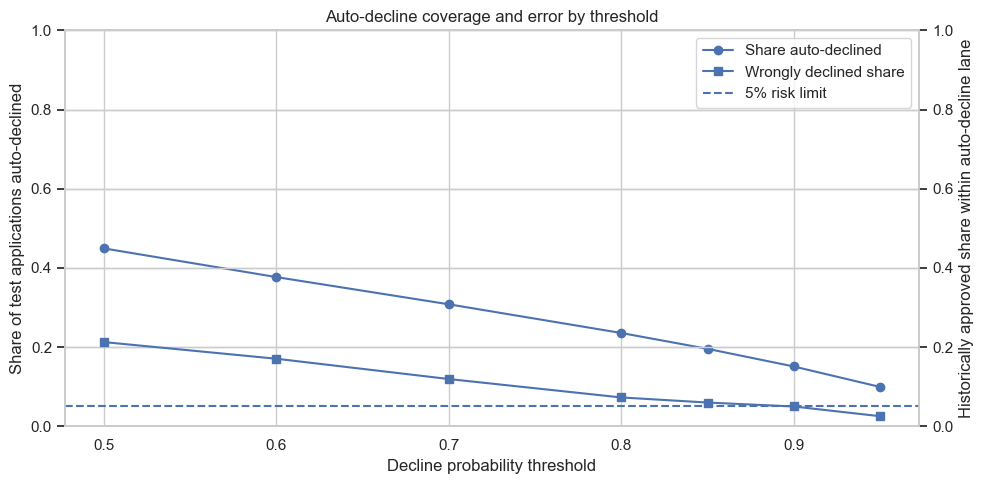

Chosen logistic-regression auto-decline threshold: 0.90


In [7]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []
y_test_array = np.asarray(y_test)

for threshold in thresholds:
    lane = p_decline_baseline >= threshold
    lane_count = int(lane.sum())
    lane_share = lane.mean()
    wrong_decline_rate = (
        float((y_test_array[lane] == 0).mean()) if lane_count else np.nan
    )
    threshold_rows.append({
        "threshold": threshold,
        "auto_decline_count_test": lane_count,
        "auto_decline_share_test": lane_share,
        "historically_approved_share_of_auto_declines": wrong_decline_rate
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.style.format({
    "auto_decline_share_test": "{:.1%}",
    "historically_approved_share_of_auto_declines": "{:.1%}"
}))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(threshold_table["threshold"], threshold_table["auto_decline_share_test"],
         marker="o", label="Share auto-declined")
ax1.set_xlabel("Decline probability threshold")
ax1.set_ylabel("Share of test applications auto-declined")
ax1.set_ylim(0, 1)
ax2 = ax1.twinx()
ax2.plot(threshold_table["threshold"],
         threshold_table["historically_approved_share_of_auto_declines"],
         marker="s", label="Wrongly declined share")
ax2.axhline(0.05, linestyle="--", label="5% risk limit")
ax2.set_ylabel("Historically approved share within auto-decline lane")
ax2.set_ylim(0, 1)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.title("Auto-decline coverage and error by threshold")
plt.tight_layout()
plt.show()

eligible = threshold_table[
    threshold_table["historically_approved_share_of_auto_declines"] <= 0.05
].copy()
if len(eligible):
    chosen_decline_threshold = eligible.sort_values(
        ["auto_decline_share_test", "threshold"], ascending=[False, True]
    ).iloc[0]["threshold"]
    print(f"Chosen logistic-regression auto-decline threshold: {chosen_decline_threshold:.2f}")
else:
    chosen_decline_threshold = None
    print("No tested threshold meets the 5% rule. Do not force an unsafe threshold; report that none qualifies.")

### Monthly business impact
The case estimates **3,000 applications per month** and **25 minutes per full manual review**. Scale the measured test-set auto-decline share to estimate monthly applications routed away from full review. Convert minutes to hours using 60 minutes per hour.

This is a planning estimate, not a guarantee of realised savings: actual impact depends on future applicant mix, analyst handling time, quality assurance and whether auto-decline is approved for use. The chosen threshold is selected on this test set because the assignment asks for that analysis; for a production evaluation, thresholds should be tuned on a separate validation set and a final test set should remain untouched.

In [8]:
MONTHLY_APPLICATIONS = 3000
MINUTES_PER_REVIEW = 25

if chosen_decline_threshold is not None:
    selected_row = threshold_table.loc[
        threshold_table["threshold"] == chosen_decline_threshold
    ].iloc[0]
    estimated_monthly_auto_declines = selected_row["auto_decline_share_test"] * MONTHLY_APPLICATIONS
    estimated_monthly_hours = estimated_monthly_auto_declines * MINUTES_PER_REVIEW / 60
    print(f"Estimated monthly applications routed to auto-decline: {estimated_monthly_auto_declines:,.0f}")
    print(f"Estimated full-review hours avoided per month: {estimated_monthly_hours:,.1f}")
else:
    print("No safe threshold found in the required grid; estimated safe auto-decline savings are 0 until a compliant threshold is identified.")

Estimated monthly applications routed to auto-decline: 453
Estimated full-review hours avoided per month: 188.5


# 5.6 — Fairness check

The model does not use `gender` as a predictor, but excluding it does not automatically make the model fair. Other variables—such as income, employment type, city tier or credit history—may correlate with gender and act as proxies.

Calculate:
1. Historical approval rate by gender, overall and within each employment type.
2. Median monthly income and share of Gig / Contract workers by gender.
3. Auto-decline rate by gender at the threshold chosen in Step 5.5.

Use this as a diagnostic, not a legal fairness certification. Compare both overall and within-group results; differences can reflect applicant mix, historical policy, measurement problems or model behaviour and require deeper review.

In [9]:
fair_df = df.copy()
fair_df["approved"] = (fair_df["decision"] == "Approved").astype(int)

print("Historical approval rate by gender:")
display(fair_df.groupby("gender")["approved"].agg(["mean", "count"]).rename(
    columns={"mean": "approval_rate", "count": "applications"}
))

print("\nHistorical approval rate by gender within employment type:")
gender_employment = (
    fair_df.groupby(["employment_type", "gender"])["approved"]
           .agg(["mean", "count"]).reset_index()
           .rename(columns={"mean": "approval_rate", "count": "applications"})
)
display(gender_employment)

print("\nMedian monthly income by gender:")
display(fair_df.groupby("gender")["monthly_income"].median().rename("median_monthly_income").to_frame())

print("\nShare of Gig / Contract workers by gender:")
gig_share = fair_df.assign(is_gig=(fair_df["employment_type"] == "Gig / Contract").astype(int)).groupby("gender")["is_gig"].mean()
display(gig_share.rename("share_gig_contract").to_frame())

if chosen_decline_threshold is not None:
    test_fair = X_test[["employment_type"]].copy()
    test_fair["gender"] = df.loc[X_test.index, "gender"]
    test_fair["auto_decline"] = (p_decline_baseline >= chosen_decline_threshold).astype(int)
    print("\nModel auto-decline rate by gender:")
    display(test_fair.groupby("gender")["auto_decline"].agg(["mean", "sum", "count"]).rename(
        columns={"mean": "auto_decline_rate", "sum": "auto_decline_count", "count": "test_applications"}
    ))
else:
    print("No threshold met the 5% limit, so no chosen-threshold gender comparison is available.")

Historical approval rate by gender:


,approval_rate,applications
gender,,
Female,0.504348,3795
Male,0.541012,8205



Historical approval rate by gender within employment type:


,employment_type,gender,approval_rate,applications
0,Business Owner,Female,0.516216,370
1,Business Owner,Male,0.510515,1379
2,Gig / Contract,Female,0.346486,811
3,Gig / Contract,Male,0.351832,955
4,Salaried,Female,0.567907,2150
5,Salaried,Male,0.590585,4907
6,Self-Employed Professional,Female,0.476293,464
7,Self-Employed Professional,Male,0.519710,964



Median monthly income by gender:


,median_monthly_income
gender,
Female,45000.0
Male,55000.0



Share of Gig / Contract workers by gender:


,share_gig_contract
gender,
Female,0.213702
Male,0.116392



Model auto-decline rate by gender:


,auto_decline_rate,auto_decline_count,test_applications
gender,,,
Female,0.156000,117,750
Male,0.148485,245,1650


### Fairness interpretation (write 3–4 sentences)
Use the outputs to answer:
- Is there a gap in historical approval rates by gender, overall or within employment types?
- Do income or employment-mix differences help describe the gap, without assuming they fully explain it?
- Does the model's auto-decline rate widen, narrow or leave the observed gap broadly unchanged?
- Should gender be used as a feature? Explain why omitting it is not sufficient by itself and why ongoing proxy/fairness monitoring is needed.

Do not claim that the model is fair merely because gender is excluded. A real deployment requires legal/compliance review, appropriate fairness metrics, sufficient sample sizes and a process for human review and appeals.

# 5.7 — Interim Briefing

Complete this as a 3–4 sentence executive summary after reviewing Steps 5.4–5.6. Replace the prompts with measured results from your notebook.

**Interim Briefing — fill in from the outputs**
1. The logistic-regression baseline achieved **[insert test accuracy]** accuracy and **[insert decline precision/recall]** precision/recall for the Declined class.
2. The recommended auto-decline threshold is **[insert threshold, or state that no tested threshold met the 5% rule]**, with an estimated **[insert monthly application count]** applications and **[insert hours]** analyst hours per month routed away from full manual review.
3. The most important risk is **[insert the main observed error or fairness issue]**.
4. Part 2 should address **[insert the key weakness, e.g. improved model discrimination, safer two-lane coverage, calibration or explainability]**.

Do not invent values. The cells above provide the values to insert.

# 5.8 — Rebuild the baseline as a single scikit-learn Pipeline

The pipeline combines imputation, scaling, one-hot encoding and logistic regression into one object. That reduces the chance that training and live applications are processed differently. It also allows raw rows to be passed through the same preprocessing logic.

**Data leakage** happens when information that would not legitimately be available at prediction time influences model fitting or evaluation—for example, fitting preprocessing on the held-out test data or including the historical `decision` in the predictors. Cross-validation must also fit preprocessing separately inside each training fold, which a pipeline helps achieve.

In [10]:
# Rebuild as a standalone pipeline using the same features and train/test split.
pipeline_preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), NUMERIC_FEATURES),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), CATEGORICAL_FEATURES)
])

baseline_pipeline = Pipeline([
    ("preprocess", pipeline_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
baseline_pipeline.fit(X_train, y_train)

pipeline_pred = baseline_pipeline.predict(X_test)
pipeline_prob = baseline_pipeline.predict_proba(X_test)[:, 1]

print("Step 5.4 accuracy:", round(accuracy_score(y_test, y_pred), 6))
print("Step 5.8 pipeline accuracy:", round(accuracy_score(y_test, pipeline_pred), 6))
print("Predictions identical:", bool(np.array_equal(y_pred, pipeline_pred)))
print("Probabilities identical (within tolerance):", bool(np.allclose(p_decline_baseline, pipeline_prob)))

# Score the five most recent applications in the dataset as raw feature rows.
recent_raw_rows = model_df.sort_values("application_date").tail(5).copy()
recent_X = recent_raw_rows[FEATURES]
recent_prob_decline = baseline_pipeline.predict_proba(recent_X)[:, 1]
recent_scored = recent_raw_rows[["application_id", "application_date"]].copy()
recent_scored["predicted_decline_probability"] = recent_prob_decline
recent_scored["predicted_approval_probability"] = 1 - recent_prob_decline
display(recent_scored)

Step 5.4 accuracy: 0.787917
Step 5.8 pipeline accuracy: 0.787917
Predictions identical: True
Probabilities identical (within tolerance): True


,application_id,application_date,predicted_decline_probability,predicted_approval_probability
11968,APP111969,2026-09-30,0.062903,0.937097
11969,APP111970,2026-09-30,0.140363,0.859637
11970,APP111971,2026-09-30,0.589141,0.410859
11959,APP111960,2026-09-30,0.781908,0.218092
11999,APP112000,2026-09-30,0.401247,0.598753


### Interpretation for Step 5.8
Explain why a packaged pipeline is safer to hand over than separate preprocessing code and a classifier. The same fitted imputers, scaler and category encoder are reused for incoming rows, including previously unseen categories handled by `handle_unknown="ignore"`. Confirm whether the pipeline reproduces the baseline; if not, investigate the difference before proceeding.

# 5.9 — Compare four models with 5-fold stratified cross-validation

Compare:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting

Use **5-fold `StratifiedKFold` cross-validation on the training split only**. Report mean ROC-AUC, accuracy, precision and recall for the Declined class. Select one model using both measured performance and explainability, then evaluate it once on the held-out test set and plot its eight most important features.

The target is `Declined = 1`, so precision and recall refer to the Declined class. ROC-AUC measures ranking ability across thresholds; it does not itself determine a safe policy threshold.

,model,mean_roc_auc,mean_accuracy,mean_precision_declined,mean_recall_declined
0,Gradient Boosting,0.889,0.800,0.813,0.747
1,Random Forest,0.884,0.795,0.796,0.759
2,Decision Tree,0.869,0.791,0.814,0.721
3,Logistic Regression,0.867,0.774,0.780,0.726


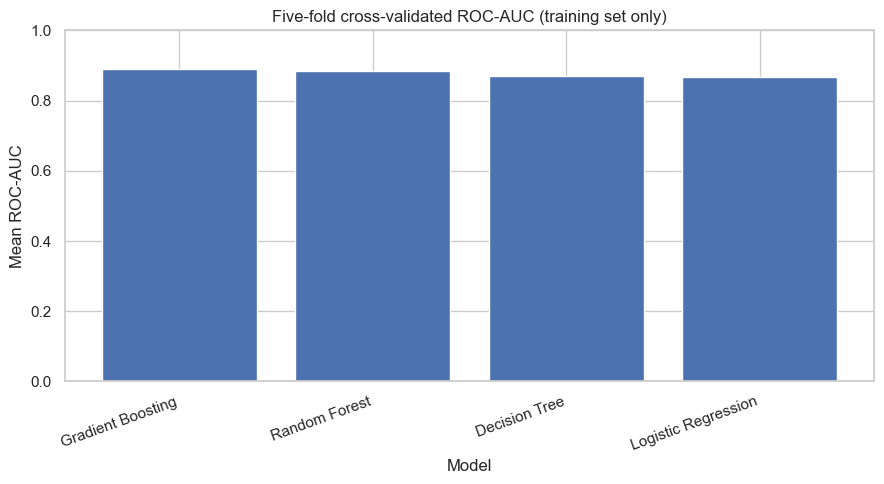

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=30, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=10, class_weight=None,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

def make_pipeline(classifier):
    prep = ColumnTransformer(transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), CATEGORICAL_FEATURES)
    ])
    return Pipeline([("preprocess", prep), ("classifier", classifier)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision_declined": "precision",
    "recall_declined": "recall"
}

cv_rows = []
cv_pipelines = {}
for name, estimator in models.items():
    pipe = make_pipeline(estimator)
    cv_pipelines[name] = pipe
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    cv_rows.append({
        "model": name,
        "mean_roc_auc": scores["test_roc_auc"].mean(),
        "mean_accuracy": scores["test_accuracy"].mean(),
        "mean_precision_declined": scores["test_precision_declined"].mean(),
        "mean_recall_declined": scores["test_recall_declined"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("mean_roc_auc", ascending=False).reset_index(drop=True)
display(cv_results.style.format({
    "mean_roc_auc": "{:.3f}",
    "mean_accuracy": "{:.3f}",
    "mean_precision_declined": "{:.3f}",
    "mean_recall_declined": "{:.3f}"
}))

plt.figure(figsize=(9, 5))
plt.bar(cv_results["model"], cv_results["mean_roc_auc"])
plt.title("Five-fold cross-validated ROC-AUC (training set only)")
plt.xlabel("Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Choose the model thoughtfully
The code below uses mean cross-validated ROC-AUC as an initial ranking aid. Before finalising the choice, review the precision/recall table and the cost of errors. A small ROC-AUC gain may not justify a less interpretable model in a credit workflow. For this educational exercise, choose the top ROC-AUC model, but explicitly discuss whether the gain over logistic regression is worth the explainability trade-off.

Selected model from training-only CV: Gradient Boosting
Held-out test ROC-AUC: 0.884
Held-out test accuracy: 0.802
Held-out test precision (Declined): 0.813
Held-out test recall (Declined): 0.751


,feature,importance_mean,importance_std
0,credit_score,0.122860,0.006037
2,foir,0.107146,0.003570
4,delinquencies_24m,0.065132,0.005414
10,employment_type,0.011225,0.001534
1,is_ntc,0.007359,0.000826
6,years_in_current_job,0.004730,0.000835
5,num_active_loans,0.004261,0.000683
11,loan_purpose,0.000798,0.000167


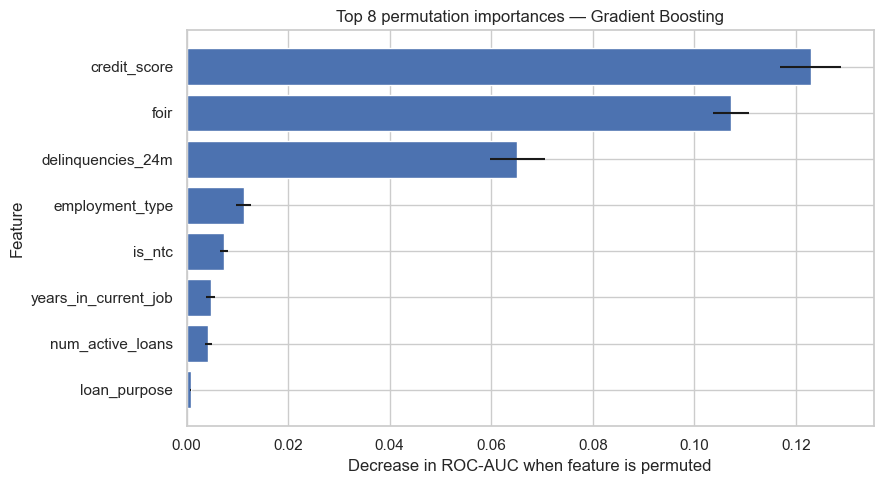

In [12]:
selected_model_name = cv_results.iloc[0]["model"]
selected_model = make_pipeline(models[selected_model_name])
selected_model.fit(X_train, y_train)

selected_test_prob_decline = selected_model.predict_proba(X_test)[:, 1]
selected_test_pred = (selected_test_prob_decline >= 0.50).astype(int)

print("Selected model from training-only CV:", selected_model_name)
print("Held-out test ROC-AUC:", round(roc_auc_score(y_test, selected_test_prob_decline), 3))
print("Held-out test accuracy:", round(accuracy_score(y_test, selected_test_pred), 3))
print("Held-out test precision (Declined):", round(precision_score(y_test, selected_test_pred, zero_division=0), 3))
print("Held-out test recall (Declined):", round(recall_score(y_test, selected_test_pred, zero_division=0), 3))

# Permutation importance on held-out data, at the original feature level.
perm = permutation_importance(
    selected_model, X_test, y_test, n_repeats=5,
    random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(8))

plt.figure(figsize=(9, 5))
top8 = importance.head(8).sort_values("importance_mean")
plt.barh(top8["feature"], top8["importance_mean"], xerr=top8["importance_std"])
plt.title(f"Top 8 permutation importances — {selected_model_name}")
plt.xlabel("Decrease in ROC-AUC when feature is permuted")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Interpretation for Step 5.9
1. State which model performed best under training-only cross-validation and by how much it differed from logistic regression.
2. Explain the trade-off between predictive performance and explainability.
3. Compare the leading model features with the descriptive patterns in credit-score and FOIR analysis.
4. Explain that feature importance measures predictive usefulness in this dataset, not causation or fairness.

The held-out test set is used here only after model selection. Threshold tuning later in this assignment uses the test labels as requested by the brief, so those threshold results are exploratory and should be confirmed on a separate validation set before any real deployment.

# 5.10 — Design the two-lane pre-screener

For the selected model and for logistic regression, use the **probability of approval**:
- **Auto-decline:** approval probability below a low threshold.
- **Fast-track:** approval probability above a high threshold.
- **Analyst review:** everything between the thresholds.

Risk limits:
- No more than **5% of auto-declined applications** may be historically approved.
- No more than **5% of fast-tracked applications** may be historically declined.

Search threshold pairs and maximise the total share outside the full manual-review lane, while meeting both limits. We evaluate threshold pairs using the held-out test split because that is what this assignment asks; a production workflow should select thresholds on validation data and confirm on an untouched test set.

,model,status,low_threshold,high_threshold,auto_decline_share,analyst_review_share,fast_track_share,wrongly_approved_share_of_auto_declines,wrongly_declined_share_of_fast_track
0,Logistic Regression,Meets both limits,0.10,0.9,0.150833,0.691250,0.157917,0.049724,0.042216
1,Gradient Boosting,Meets both limits,0.15,0.9,0.226667,0.597917,0.175417,0.044118,0.042755


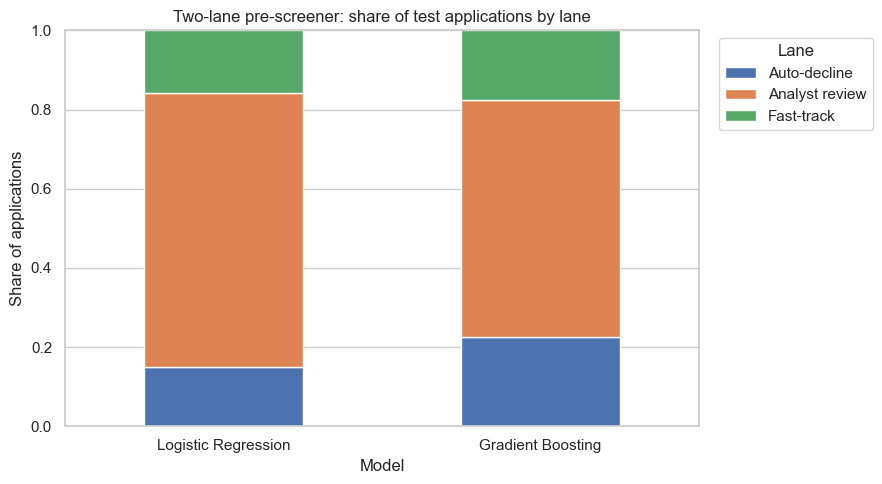

In [13]:
p_approve_logistic = 1 - p_decline_baseline
p_approve_selected = 1 - selected_test_prob_decline

def search_two_lane_thresholds(y_true, p_approve, max_error=0.05):
    y_true = np.asarray(y_true)  # 0=Approved, 1=Declined
    # Candidate thresholds from probability quantiles plus fixed endpoints.
    candidates = np.unique(np.r_[np.linspace(0.05, 0.95, 37), np.quantile(p_approve, np.linspace(0, 1, 41))])
    best = None
    rows = []
    for low in candidates:
        auto_mask = p_approve < low
        n_auto = int(auto_mask.sum())
        auto_error = float((y_true[auto_mask] == 0).mean()) if n_auto else np.nan
        for high in candidates:
            if high <= low:
                continue
            fast_mask = p_approve > high
            n_fast = int(fast_mask.sum())
            fast_error = float((y_true[fast_mask] == 1).mean()) if n_fast else np.nan
            safe_auto = n_auto > 0 and auto_error <= max_error
            safe_fast = n_fast > 0 and fast_error <= max_error
            if safe_auto and safe_fast:
                coverage = (n_auto + n_fast) / len(y_true)
                rows.append({
                    "low_threshold": float(low),
                    "high_threshold": float(high),
                    "auto_count": n_auto,
                    "review_count": int(len(y_true) - n_auto - n_fast),
                    "fast_count": n_fast,
                    "auto_share": n_auto / len(y_true),
                    "review_share": (len(y_true) - n_auto - n_fast) / len(y_true),
                    "fast_share": n_fast / len(y_true),
                    "auto_error_rate": auto_error,
                    "fast_error_rate": fast_error,
                    "automated_share": coverage
                })
                if best is None or coverage > best["automated_share"]:
                    best = rows[-1]
    return best, pd.DataFrame(rows)

best_logistic_lanes, all_logistic_lanes = search_two_lane_thresholds(y_test, p_approve_logistic)
best_selected_lanes, all_selected_lanes = search_two_lane_thresholds(y_test, p_approve_selected)

def lane_summary(best, name):
    if best is None:
        return {"model": name, "status": "No threshold pair met both 5% limits"}
    return {
        "model": name,
        "status": "Meets both limits",
        "low_threshold": best["low_threshold"],
        "high_threshold": best["high_threshold"],
        "auto_decline_share": best["auto_share"],
        "analyst_review_share": best["review_share"],
        "fast_track_share": best["fast_share"],
        "wrongly_approved_share_of_auto_declines": best["auto_error_rate"],
        "wrongly_declined_share_of_fast_track": best["fast_error_rate"]
    }

lane_comparison = pd.DataFrame([
    lane_summary(best_logistic_lanes, "Logistic Regression"),
    lane_summary(best_selected_lanes, selected_model_name)
])
display(lane_comparison)

# Stacked bar: lane shares for both models, using the best safe pair found.
plot_rows = []
for name, best in [("Logistic Regression", best_logistic_lanes), (selected_model_name, best_selected_lanes)]:
    if best is not None:
        plot_rows.append({
            "model": name,
            "Auto-decline": best["auto_share"],
            "Analyst review": best["review_share"],
            "Fast-track": best["fast_share"]
        })

if plot_rows:
    plot_df = pd.DataFrame(plot_rows).set_index("model")
    ax = plot_df[["Auto-decline", "Analyst review", "Fast-track"]].plot(
        kind="bar", stacked=True, figsize=(9, 5)
    )
    ax.set_title("Two-lane pre-screener: share of test applications by lane")
    ax.set_ylabel("Share of applications")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 1)
    ax.legend(title="Lane", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No model found a threshold pair meeting both 5% risk limits.")

### Translate lane shares into monthly impact
The automated share is the combined share of auto-decline and fast-track. For the assignment's planning estimate, multiply each lane share by 3,000 applications/month. Estimate full-review hours avoided using 25 minutes per application. Fast-track is **not** assumed to require zero work; it receives a light-touch check, so the calculation estimates full manual reviews avoided rather than total labour saved.

In [14]:
def monthly_lane_impact(best, model_name):
    if best is None:
        return {
            "model": model_name, "monthly_auto_declines": np.nan,
            "monthly_analyst_reviews": np.nan, "monthly_fast_track": np.nan,
            "estimated_full_review_hours_avoided": np.nan
        }
    auto_n = best["auto_share"] * MONTHLY_APPLICATIONS
    review_n = best["review_share"] * MONTHLY_APPLICATIONS
    fast_n = best["fast_share"] * MONTHLY_APPLICATIONS
    hours_avoided = (auto_n + fast_n) * MINUTES_PER_REVIEW / 60
    return {
        "model": model_name,
        "monthly_auto_declines": round(auto_n),
        "monthly_analyst_reviews": round(review_n),
        "monthly_fast_track": round(fast_n),
        "estimated_full_review_hours_avoided": round(hours_avoided, 1)
    }

display(pd.DataFrame([
    monthly_lane_impact(best_logistic_lanes, "Logistic Regression"),
    monthly_lane_impact(best_selected_lanes, selected_model_name)
]))

,model,monthly_auto_declines,monthly_analyst_reviews,monthly_fast_track,estimated_full_review_hours_avoided
0,Logistic Regression,453,2074,474,385.9
1,Gradient Boosting,680,1794,526,502.6


### Interpretation for Step 5.10
Compare the two models' safe lane shares and error rates. A model that routes more applications out of full review is not automatically better if it does so by violating either 5% risk limit. If no threshold pair meets both limits, state that honestly; the model should not be forced into an unsafe automated lane.

The threshold search is a finite grid, so it finds the best safe pair among the candidates it evaluated, not a mathematical guarantee over every possible real-valued pair. In a real policy, include confidence intervals, subgroup checks, calibration and a monitored pilot.

# 5.11 — Credit Policy Recommendation

Use the measured outputs from Steps 5.9 and 5.10 to complete this 6–8 sentence recommendation for the Credit Policy Analyst to forward to the Head of Retail Lending.

**Recommendation template — fill with actual notebook results**
1. I recommend **[model]** because its five-fold training cross-validation ROC-AUC was **[value]**, compared with **[value]** for logistic regression; the performance gain **[does/does not]** justify its explainability trade-off.
2. The proposed auto-decline and fast-track approval-probability thresholds are **[low]** and **[high]**, respectively, and the lanes would handle **[auto %]**, **[review %]** and **[fast %]** of applications in the test set.
3. Both lanes **[meet/do not meet]** the policy limits: the historical approval share within auto-decline is **[value]**, and the historical decline share within fast-track is **[value]**.
4. At 3,000 applications per month, this is approximately **[number]** auto-declines, **[number]** fast-track cases and **[number]** applications retained for full analyst review, avoiding an estimated **[hours]** full-review hours.
5. The principal go-live risks are **[observed errors, distribution shift, data quality, threshold instability or explainability limitations]**; applicants with missing/uncertain information, unusual profiles, borderline probabilities or any legally/operationally designated vulnerable cases should remain with a human.
6. Gender is excluded from predictors, but proxy effects and outcome disparities remain possible; the bank should monitor lane rates and error rates by gender and relevant intersections, investigate gaps, and retain a documented human-review and appeal process.
7. Before full rollout, I would run a time-based out-of-sample validation and a controlled shadow pilot, verify calibration and data quality, and obtain credit-policy, risk and compliance approval.

**Do not submit the placeholders unchanged.** Replace every bracketed item with results printed by the notebook and make the recommendation match the evidence.

# 5.12 — Optional stretch: Where does the model struggle?

Use K-Means to segment applicants using scaled `monthly_income`, `credit_score`, `foir`, `years_in_current_job` and `age`. Use an elbow plot to help choose a cluster count, give each segment a business name, and report segment size, historical approval rate and selected-model error rate on the test set.

**Important:** this is a post-modelling diagnostic. Do not feed cluster labels back into the predictive model. Missing credit scores are imputed for clustering, while `is_ntc` can help interpret segments; this can make NTC applicants look numerically similar to scored applicants, so interpret carefully.

  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


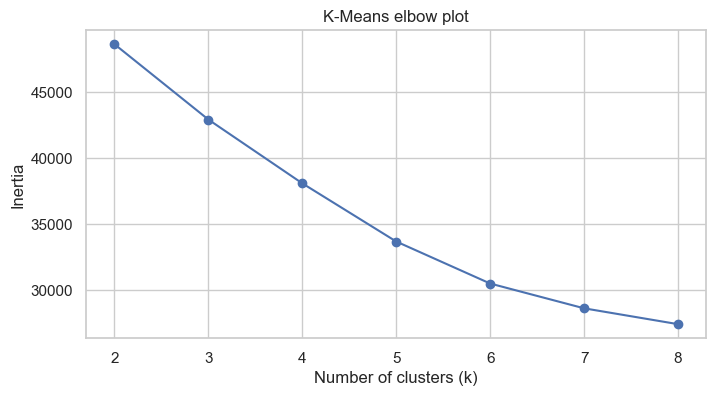

,applicant_cluster,applications,median_income,median_credit_score,median_foir,median_job_years,median_age,approval_rate
0,0,1736,112000.0,730.0,0.306471,3.2,36.0,0.591590
1,1,5861,42500.0,714.0,0.276364,2.0,29.0,0.539328
2,2,1841,49000.0,730.0,0.652830,2.7,34.0,0.228137
3,3,2562,54250.0,743.0,0.294826,7.0,39.0,0.681109


,applicant_cluster,test_applications,test_error_rate,historical_approval_rate
0,0,330,0.260606,0.606061
1,1,1160,0.201724,0.533621
2,2,381,0.141732,0.215223
3,3,529,0.192817,0.699433


In [15]:
CLUSTER_FEATURES = ["monthly_income", "credit_score", "foir", "years_in_current_job", "age"]
cluster_data = df[CLUSTER_FEATURES].copy()
cluster_data["credit_score"] = cluster_data["credit_score"].fillna(cluster_data["credit_score"].median())
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan)
cluster_data = cluster_data.fillna(cluster_data.median(numeric_only=True))

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

inertias = []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(cluster_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("K-Means elbow plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.show()

# Choose a practical starting point after inspecting the elbow plot.
# Change this value if the elbow plot suggests another cluster count.
CHOSEN_K = 4
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
df["applicant_cluster"] = kmeans.fit_predict(cluster_scaled)

cluster_summary = (
    df.groupby("applicant_cluster")
      .agg(
          applications=("application_id", "count"),
          median_income=("monthly_income", "median"),
          median_credit_score=("credit_score", "median"),
          median_foir=("foir", "median"),
          median_job_years=("years_in_current_job", "median"),
          median_age=("age", "median"),
          approval_rate=("decision", lambda s: (s == "Approved").mean())
      )
      .reset_index()
)
display(cluster_summary)

# Score the test split with the selected model and connect errors to the applicant segments.
test_cluster_map = df.loc[X_test.index, ["applicant_cluster", "decision"]].copy()
test_cluster_map["actual_declined"] = np.asarray(y_test)
test_cluster_map["predicted_declined"] = selected_test_pred
test_cluster_map["is_error"] = (test_cluster_map["actual_declined"] != test_cluster_map["predicted_declined"]).astype(int)
cluster_test_errors = test_cluster_map.groupby("applicant_cluster").agg(
    test_applications=("is_error", "size"),
    test_error_rate=("is_error", "mean"),
    historical_approval_rate=("decision", lambda s: (s == "Approved").mean())
).reset_index()
display(cluster_test_errors)

### Optional stretch interpretation
Give each cluster a business label only after examining its profile (for example, “higher income / established credit” or “thin-file / early-career” if the actual summary supports that description). Identify the segment with the highest test error rate or an especially concerning profile and explain why it should receive human review. Do not assume a cluster is risky merely because of its label; use the measured approval and error rates and consider sample size.

# Final checklist before submission
- [ ] CSV and notebook are in the same folder.
- [ ] Restart the kernel and run every cell from top to bottom.
- [ ] Review and explain every cleaning decision.
- [ ] Keep applicants with missing credit scores and use the NTC flag.
- [ ] Report confusion-matrix counts in business language.
- [ ] Apply the 5% auto-decline and fast-track limits.
- [ ] Cross-validate only on the training set.
- [ ] Discuss explainability, fairness, data leakage and human review.
- [ ] Replace all recommendation placeholders with measured results.
- [ ] Submit this notebook plus a one-page insight summary (maximum 400 words for an individual submission).